# Exploring 2024 NYC yellow-taxi trips

What drives a metered fare, looked at on a random sample of about 100,000 trips from each month of 2024, cleaned with the same filters the training notebook uses. Plots are saved to `plots/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from taxi_data import load_hourly_weather, load_trips, load_zones, save_plot

sns.set_theme(style="whitegrid")
zones, weather = load_zones(), load_hourly_weather()
trips = pd.concat([load_trips(m, zones, weather, sample_fraction=0.035) for m in range(1, 13)], ignore_index=True)
trips["fare_per_mile"] = trips.fare_amount / trips.trip_miles
print(f"{len(trips):,} trips")
trips[["fare_amount", "trip_miles", "trip_time", "implied_speed_mph"]].describe().round(2)

1,365,423 trips


,fare_amount,trip_miles,trip_time,implied_speed_mph
count,1365423.00,1365423.00,1365423.00,1365423.00
mean,19.50,3.38,1014.18,10.83
std,16.27,4.27,820.67,6.23
min,2.51,0.11,61.00,0.08
25%,9.30,1.07,480.00,6.87
50%,14.20,1.80,785.00,9.27
75%,22.60,3.40,1267.00,12.75
max,322.90,80.00,14383.00,75.00


## Fares

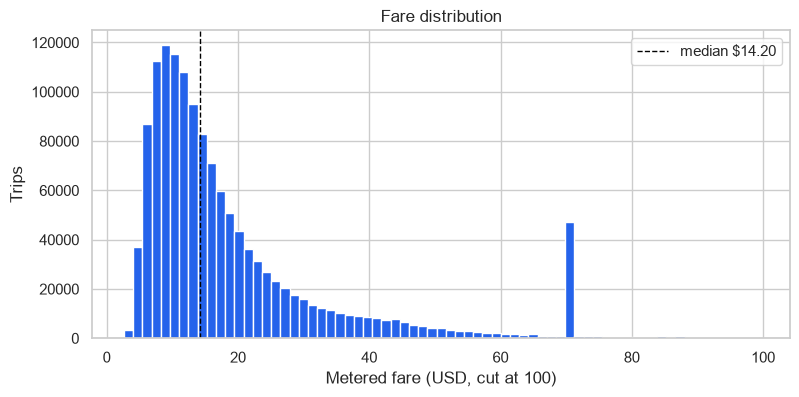

Mean $19.50, median $14.20
Share of trips at exactly $70 (JFK flat fare): 3.4%


In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
# Meter fares move in $0.70 steps from a $3.00 start, so bins two steps wide
# and offset by half a step hold the same number of possible fares each.
ax.hist(trips.fare_amount, bins=np.arange(2.65, 100, 1.4), color="#2563eb")
ax.axvline(trips.fare_amount.median(), color="black", linestyle="--", linewidth=1,
           label=f"median ${trips.fare_amount.median():.2f}")
ax.set_xlabel("Metered fare (USD, cut at 100)")
ax.set_ylabel("Trips")
ax.set_title("Fare distribution")
ax.legend()
save_plot(fig, "fare_distribution")
plt.show()

print(f"Mean ${trips.fare_amount.mean():.2f}, median ${trips.fare_amount.median():.2f}")
print(f"Share of trips at exactly $70 (JFK flat fare): {(trips.fare_amount == 70).mean():.1%}")

Fares are right-skewed: half are under about $14, the mean is pulled up to about $19.50 by airport runs. The spike at $70 is the flat fare between Manhattan and JFK, about 3% of trips. The model doesn't have to learn it; the API applies the flat rate as a rule.

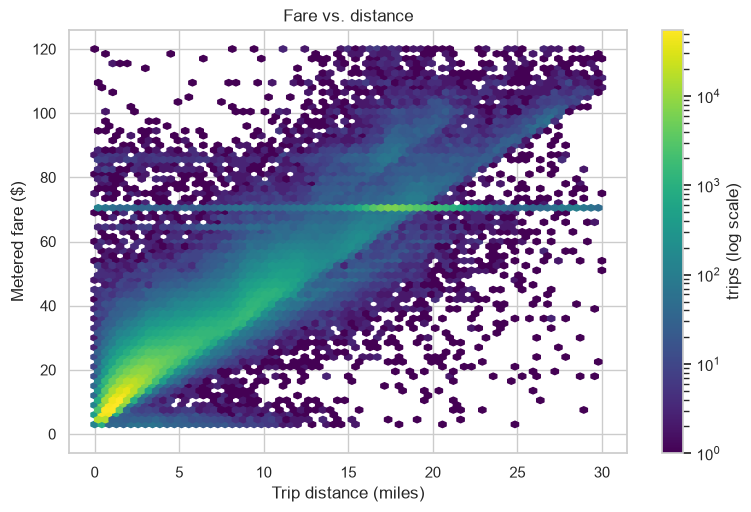

Correlation of fare with distance: 0.946, with duration: 0.855


In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
hb = ax.hexbin(trips.trip_miles, trips.fare_amount, gridsize=70, bins="log", cmap="viridis",
               extent=(0, 30, 0, 120), mincnt=1)
ax.set_xlabel("Trip distance (miles)")
ax.set_ylabel("Metered fare ($)")
ax.set_title("Fare vs. distance")
fig.colorbar(hb, label="trips (log scale)")
save_plot(fig, "fare_vs_distance")
plt.show()
print(f"Correlation of fare with distance: {trips.fare_amount.corr(trips.trip_miles):.3f}, "
      f"with duration: {trips.fare_amount.corr(trips.trip_time):.3f}")

Distance and duration both track the fare closely (correlations of about 0.95 and 0.86), and they're strongly correlated with each other. The spread above the main diagonal is slow traffic, where the meter charges by the minute instead of the mile. The horizontal line is the JFK flat fare again.

## Where trips go

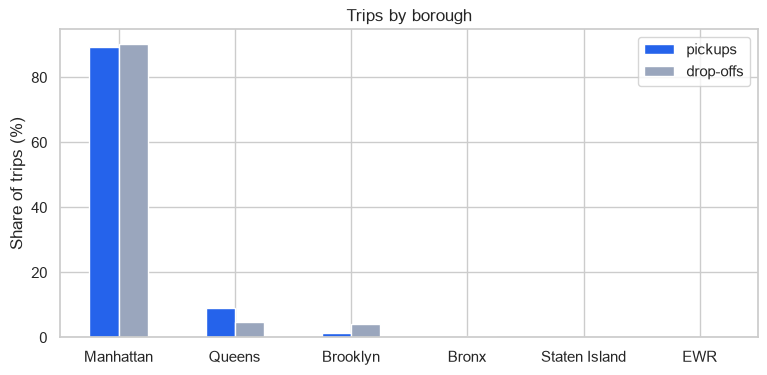

,pickups,drop-offs
Manhattan,89.4,90.2
Queens,8.9,4.8
Brooklyn,1.4,4.1
Bronx,0.3,0.6
Staten Island,0.0,0.0
EWR,0.0,0.3


In [4]:
by_borough = pd.DataFrame({
    "pickups": trips.PU_Borough.value_counts(normalize=True),
    "drop-offs": trips.DO_Borough.value_counts(normalize=True),
}).fillna(0).sort_values("pickups", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
(100 * by_borough).plot.bar(ax=ax, rot=0, color=["#2563eb", "#9aa6bd"])
ax.set_ylabel("Share of trips (%)")
ax.set_xlabel("")
ax.set_title("Trips by borough")
save_plot(fig, "trips_by_borough")
plt.show()
(100 * by_borough).round(1)

About 90% of trips start and end in Manhattan, and most of the rest are Queens pickups, mainly from JFK and LaGuardia. The other boroughs are thin, which is why the route-level fare history needs smoothing toward the overall mean.

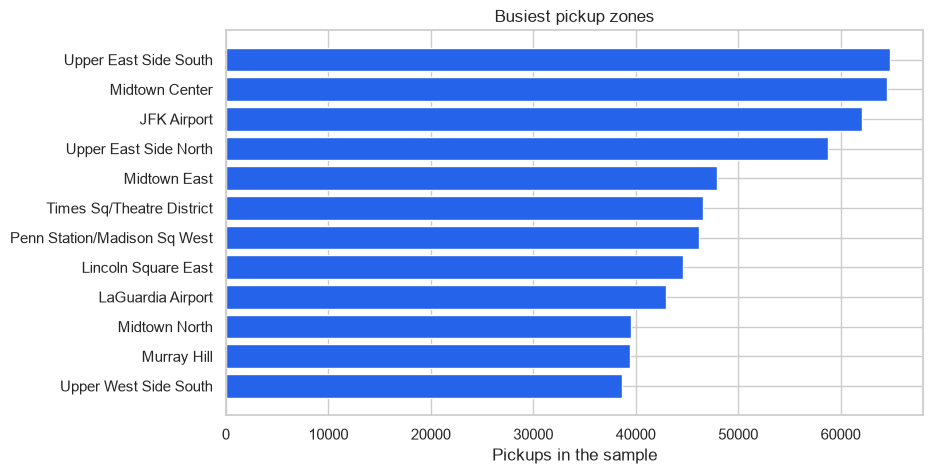

In [5]:
top_zones = trips.PU_Zone.value_counts().head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_zones.index, top_zones.values, color="#2563eb")
ax.set_xlabel("Pickups in the sample")
ax.set_title("Busiest pickup zones")
save_plot(fig, "top_pickup_zones")
plt.show()

## Time of day

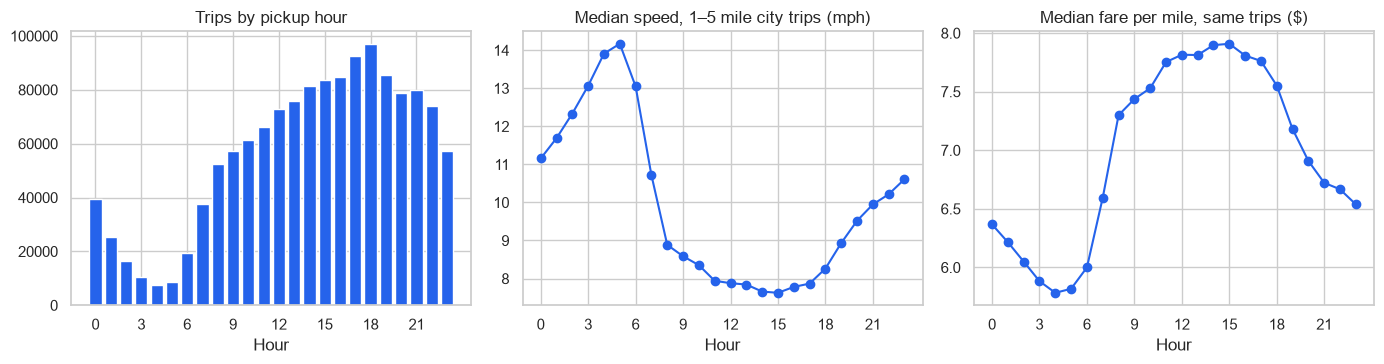

request_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
trips,39451.00,25277.00,16399.00,10570.00,7655.00,8501.00,19243.00,37756.00,52365.00,57236.00,...,81509.00,83638.00,84771.00,92434.00,96860.00,85673.00,78663.00,79919.00,74166.00,57203.00
speed,11.15,11.69,12.34,13.07,13.91,14.17,13.05,10.72,8.89,8.59,...,7.66,7.63,7.78,7.87,8.26,8.93,9.52,9.95,10.21,10.61
fare_per_mile,6.37,6.22,6.05,5.88,5.78,5.82,6.00,6.60,7.30,7.44,...,7.90,7.91,7.81,7.76,7.55,7.18,6.91,6.72,6.67,6.54


In [6]:
city = trips[(trips.trip_miles.between(1, 5)) & ~trips.is_airport_trip.astype(bool)]
hourly = pd.DataFrame({
    "trips": trips.groupby("request_hour").size(),
    "speed": city.groupby("request_hour").implied_speed_mph.median(),
    "fare_per_mile": city.groupby("request_hour").fare_per_mile.median(),
})

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].bar(hourly.index, hourly.trips, color="#2563eb")
axes[0].set_title("Trips by pickup hour")
axes[1].plot(hourly.index, hourly.speed, marker="o", color="#2563eb")
axes[1].set_title("Median speed, 1–5 mile city trips (mph)")
axes[2].plot(hourly.index, hourly.fare_per_mile, marker="o", color="#2563eb")
axes[2].set_title("Median fare per mile, same trips ($)")
for ax in axes:
    ax.set_xlabel("Hour")
    ax.set_xticks(range(0, 24, 3))
fig.tight_layout()
save_plot(fig, "time_of_day")
plt.show()
hourly.round(2).T

The meter charges by time when the cab is slower than 12 mph, so traffic raises the price of the same distance. For 1–5 mile city trips, median speed falls from about 14 mph at 5 AM to under 8 mph in the afternoon, and the median fare per mile rises from about $5.80 to $7.90. That's the reason for the `implied_speed_mph` and `request_hour` features.

## Weather

In [7]:
city = city.assign(conditions=np.select(
    [city.snow > 0, city.precip >= 1, city.precip > 0], ["snow", "rain ≥ 1 mm/h", "light rain"], "dry"))
city.groupby("conditions").agg(
    trips=("fare_amount", "size"),
    median_speed_mph=("implied_speed_mph", "median"),
    median_fare_per_mile=("fare_per_mile", "median"),
).round(2)

,trips,median_speed_mph,median_fare_per_mile
conditions,,,
dry,705181,8.94,7.20
light rain,84341,8.69,7.38
rain ≥ 1 mm/h,34324,8.52,7.50
snow,8486,9.34,7.10


Weather has a small effect. In rain of at least 1 mm an hour, city trips are about 5% slower and about 4% more expensive per mile than in dry weather. Snow hours are rare in 2024 and show no clear effect.

## Correlations

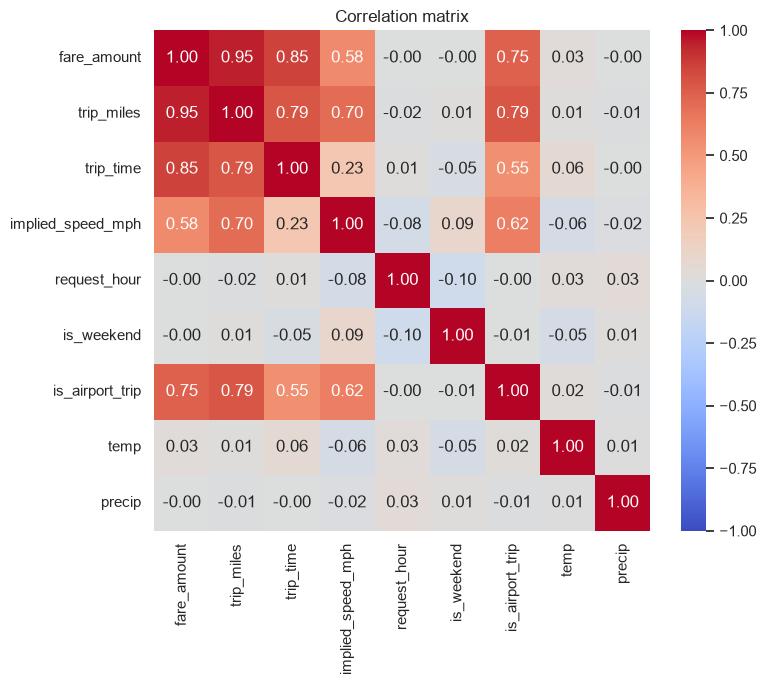

In [8]:
cols = ["fare_amount", "trip_miles", "trip_time", "implied_speed_mph", "request_hour",
        "is_weekend", "is_airport_trip", "temp", "precip"]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(trips[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
save_plot(fig, "correlations")
plt.show()